## 功率谱密度特征分析，作为 Adaptive Spectral Modulation (ASM) module 的神经生理学基础

-注：以下内容在本地运行

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt


# 设置字体为Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['axes.unicode_minus'] = False

### 参数设置

In [2]:
# 定义根目录路径
data_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature")
save_path = Path(r"C:\Python_Code\ADMamba\figs")
label_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI Label.xlsx")

# 检查路径是否存在
if not data_path.exists():
    raise FileNotFoundError(f"路径不存在: {data_path}")

# 创建保存目录
save_path.mkdir(parents=True, exist_ok=True)

# 定义通道顺序
channel_order = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'F7', 'F8', 'Cz', 'C3', 'C4',
                 'T7', 'T8', 'Pz', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2']

# 定义范式列表和状态列表
assessments = ['Assess-01']
paradigms = ['resting state after', 'resting state befor']
states = ['open eyes']

# 横坐标固定显示的频率刻度（Hz）
FREQ_TICK_HZ = [4, 8, 13, 30, 45]

### 数据读取 与 预处理

In [3]:
# 读取标签文件，获取受试者信息和分类标签
valid_subjects = set()  # 存储标签文件中的受试者名单
subject_info = {}  # 存储受试者的详细信息

if label_path.exists():
    try:
        label_df = pd.read_excel(label_path)
        
        # 构建subject_info字典
        # 结构: subject_info[subject_name] = {
        #   '编号': id, '性别': gender, '年龄': age, '文化程度': education,
        #   'Assess-01': {'标签': label1, 'MoCA': moca1, 'MMSE': mmse1},
        #   'Assess-02': {'标签': label2, 'MoCA': moca2, 'MMSE': mmse2}
        # }
        for idx, row in label_df.iterrows():
            subject_name = str(row['英文名']).strip() if pd.notna(row['英文名']) else None
            if subject_name:
                valid_subjects.add(subject_name)
                subject_info[subject_name] = {
                    '编号': row['编号'] if pd.notna(row['编号']) else None,
                    '性别': str(row['性别']).strip() if pd.notna(row['性别']) else None,
                    '年龄': row['年龄'] if pd.notna(row['年龄']) else None,
                    '文化程度': str(row['文化程度']).strip() if pd.notna(row['文化程度']) else None,
                    'Assess-01': {
                        '标签': str(row['标签 1']).strip() if pd.notna(row['标签 1']) else None,
                        'MoCA': row['MoCA 1'] if pd.notna(row['MoCA 1']) else None,
                        'MMSE': row['MMSE 1'] if pd.notna(row['MMSE 1']) else None
                    }
                }
        print(f"从标签文件中读取到 {len(valid_subjects)} 个受试者")
        print(f"受试者名单: {sorted(list(valid_subjects))[:10]}{'...' if len(valid_subjects) > 10 else ''}")
    except Exception as e:
        print(f"警告: 读取标签文件失败 - {str(e)}")
        print("将处理所有找到的受试者数据")
else:
    print(f"警告: 标签文件不存在 - {label_path}")
    print("将处理所有找到的受试者数据")

从标签文件中读取到 111 个受试者
受试者名单: ['Tianshiting', 'baijin', 'chaizhaoji', 'chenfukang', 'congshuren', 'dengqing', 'dingyouxiang', 'dujiansun', 'dujingxian', 'fenglihui']...


In [4]:
# 辅助函数：根据受试者名称和评估期获取类别
def get_subject_category(subject_name, assess='Assess-01', category_type='binary'):
    """
    根据受试者名称和评估期获取类别
    
    参数:
    - subject_name: 受试者名称
    - assess: 评估期，'Assess-01' 或 'Assess-02'
    - category_type: 分类类型，'binary'（Normal/Abnormal）或 'ternary'（NC/MCI/AD）
    
    返回:
    - 类别字符串：
      - binary模式: 'Normal'、'Abnormal' 或 None
      - ternary模式: 'NC'、'MCI'、'AD' 或 None
    """
    if not subject_info or subject_name not in subject_info:
        return None
    
    label = subject_info[subject_name].get(assess, {}).get('标签')
    if not label:
        return None
    
    label_upper = str(label).upper().strip()
    
    if category_type == 'binary':
        # 二分类：Normal vs Abnormal
        if label_upper in ['AD', 'MCI', 'D']:
            return 'Abnormal'
        else:
            return 'Normal'
    elif category_type == 'ternary':
        # 三分类：NC, MCI, AD
        if label_upper == 'AD' or label_upper == 'D':
            return 'AD'
        elif label_upper == 'MCI':
            return 'MCI'
        else:
            return 'HC'
    else:
        return None

In [5]:
# 用于存储找到的文件路径
# 结构: neural_markers_files[paradigm][state][assess][subject] = file_path
neural_markers_files = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

# 遍历所有范式、状态和评估期
for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            # 构建完整路径: data_path / assess / paradigm / state
            current_path = data_path / assess / paradigm / state
            
            if not current_path.exists():
                print(f"警告: {current_path} 不存在，跳过")
                continue
            
            print(f"\n正在扫描 {assess} / {paradigm} / {state} ...")
            
            # 遍历该路径下的所有子文件夹（受试者文件夹）
            for subject_folder in current_path.iterdir():
                if subject_folder.is_dir():
                    neural_marker_file = subject_folder / "Neural_Markers.npz"
                    
                    if neural_marker_file.exists():
                        subject_name = subject_folder.name
                        # 只处理标签文件中的受试者
                        if valid_subjects and subject_name not in valid_subjects:
                            print(f"  跳过: {subject_name} (不在标签文件中)")
                            continue
                        neural_markers_files[paradigm][state][assess][subject_name] = neural_marker_file
                        print(f"  找到: {subject_name} -> {neural_marker_file}")
                    else:
                        print(f"  警告: {subject_folder.name} 文件夹中没有找到 Neural_Markers.npz")

# 打印统计信息
print("\n" + "="*80)
print("统计信息:")
for paradigm in paradigms:
    for state in states:
        count_01 = len(neural_markers_files[paradigm][state]['Assess-01'])
        print(f"{paradigm} / {state}:")
        print(f"  Assess-01: {count_01} 个文件")
print("="*80)


正在扫描 Assess-01 / resting state after / open eyes ...
  找到: baijin -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\baijin\Neural_Markers.npz
  找到: chaizhaoji -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\chaizhaoji\Neural_Markers.npz
  找到: chenfukang -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\chenfukang\Neural_Markers.npz
  找到: congshuren -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\congshuren\Neural_Markers.npz
  找到: dengqing -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\dengqing\Neural_Markers.npz
  找到: dingyouxiang -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state after\open eyes\dingyouxiang\Neural_Markers.npz
  找到: dujiansun -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Ass

In [6]:
# 读取所有 Neural_Markers.npz 文件中的 PSD Avg 数据
# 结构: psd_data[paradigm][state][assess][subject] = psd_array (n_channels, n_freqs)
psd_data = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

print("\n开始读取 PSD Avg 数据...")
for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            for subject_name, file_path in neural_markers_files[paradigm][state][assess].items():
                try:
                    data = np.load(file_path, allow_pickle=True)
                    if 'PSD Avg' in data:
                        psd_data[paradigm][state][assess][subject_name] = data['PSD Avg']
                        print(f"  成功读取: {paradigm} / {state} / {assess} / {subject_name}")
                    else:
                        print(f"  警告: {file_path} 中没有找到 'PSD Avg' 数据")
                except Exception as e:
                    print(f"  错误: 读取 {file_path} 失败 - {str(e)}")

print(f"\n成功读取 {sum(len(psd_data[p][s][a]) for p in paradigms for s in states for a in assessments)} 个受试者的 PSD Avg 数据")


开始读取 PSD Avg 数据...
  成功读取: resting state after / open eyes / Assess-01 / baijin
  成功读取: resting state after / open eyes / Assess-01 / chaizhaoji
  成功读取: resting state after / open eyes / Assess-01 / chenfukang
  成功读取: resting state after / open eyes / Assess-01 / congshuren
  成功读取: resting state after / open eyes / Assess-01 / dengqing
  成功读取: resting state after / open eyes / Assess-01 / dingyouxiang
  成功读取: resting state after / open eyes / Assess-01 / dujiansun
  成功读取: resting state after / open eyes / Assess-01 / dujingxian
  成功读取: resting state after / open eyes / Assess-01 / fenglihui
  成功读取: resting state after / open eyes / Assess-01 / fengyeheng
  成功读取: resting state after / open eyes / Assess-01 / gaomeizhu
  成功读取: resting state after / open eyes / Assess-01 / gaotonghuai
  成功读取: resting state after / open eyes / Assess-01 / gedeyun
  成功读取: resting state after / open eyes / Assess-01 / gujinfen
  成功读取: resting state after / open eyes / Assess-01 / guozhonggen
  成功读取: resting

In [7]:
# 直接使用原始PSD数据，不进行转换
# 结构: psd_normalized[paradigm][state][assess][subject] = psd_array (n_channels, n_freqs)
psd_normalized = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

print("\n开始复制原始PSD数据...")
for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            for subject_name, psd_array in psd_data[paradigm][state][assess].items():
                # psd_array 形状: (n_channels, n_freqs)
                # 直接使用原始数据，不进行任何转换
                psd_normalized[paradigm][state][assess][subject_name] = psd_array.copy()
                print(f"  已复制: {paradigm} / {state} / {assess} / {subject_name}")

print("原始PSD数据复制完成！")


开始复制原始PSD数据...
  已复制: resting state after / open eyes / Assess-01 / baijin
  已复制: resting state after / open eyes / Assess-01 / chaizhaoji
  已复制: resting state after / open eyes / Assess-01 / chenfukang
  已复制: resting state after / open eyes / Assess-01 / congshuren
  已复制: resting state after / open eyes / Assess-01 / dengqing
  已复制: resting state after / open eyes / Assess-01 / dingyouxiang
  已复制: resting state after / open eyes / Assess-01 / dujiansun
  已复制: resting state after / open eyes / Assess-01 / dujingxian
  已复制: resting state after / open eyes / Assess-01 / fenglihui
  已复制: resting state after / open eyes / Assess-01 / fengyeheng
  已复制: resting state after / open eyes / Assess-01 / gaomeizhu
  已复制: resting state after / open eyes / Assess-01 / gaotonghuai
  已复制: resting state after / open eyes / Assess-01 / gedeyun
  已复制: resting state after / open eyes / Assess-01 / gujinfen
  已复制: resting state after / open eyes / Assess-01 / guozhonggen
  已复制: resting state after / open 

In [8]:
# 异常值检查：将所有同类被试的同一通道的数据汇聚起来，检查异常值
# 如果某个被试在某个通道存在异常值，则删除这个被试的所有数据
print("\n开始进行异常值检查...")

def detect_outliers_iqr(data, lower_bound_factor=1.5, upper_bound_factor=1.5):
    """
    使用IQR方法检测异常值（类似箱线图的异常值检测）
    
    参数:
    - data: 一维数组
    - lower_bound_factor: 下界倍数（默认1.5）
    - upper_bound_factor: 上界倍数（默认1.5）
    
    返回:
    - 布尔数组，True表示异常值
    """
    if len(data) < 3:
        return np.zeros_like(data, dtype=bool)
    
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1
    
    if iqr == 0:
        # 如果IQR为0，使用标准差方法
        mean = np.mean(data)
        std = np.std(data)
        if std == 0:
            return np.zeros_like(data, dtype=bool)
        lower_bound = mean - 3 * std
        upper_bound = mean + 3 * std
    else:
        lower_bound = q1 - lower_bound_factor * iqr
        upper_bound = q3 + upper_bound_factor * iqr
    
    outliers = (data < lower_bound) | (data > upper_bound)
    return outliers

# 记录需要处理的异常值（只删除异常值，不删除整个被试）
# outliers_to_remove: (paradigm, state, assess, subject_name, ch_idx)
outliers_to_remove = set()
total_outliers_found = 0

# 按类别和通道进行异常值检测
for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            # 先按类别分组
            for category_type in ['ternary']:
                # 收集每个类别每个通道的所有被试数据
                # category_channel_data[category][ch_idx] = [(subject_name, channel_statistic), ...]
                # 使用通道的统计量（如平均值）来代表该通道的数据
                category_channel_data = defaultdict(lambda: defaultdict(list))
                
                for subject_name, psd_array in psd_normalized[paradigm][state][assess].items():
                    category = get_subject_category(subject_name, assess=assess, category_type=category_type)
                    if category is None:
                        continue
                    
                    n_channels, n_freqs = psd_array.shape
                    for ch_idx in range(n_channels):
                        channel_psd = psd_array[ch_idx, :]  # 该通道的PSD数据（n_freqs,）
                        # 计算该通道的统计量（使用平均值作为代表值）
                        channel_mean = np.mean(channel_psd)
                        category_channel_data[category][ch_idx].append((subject_name, channel_mean))
                
                # 对每个类别每个通道进行异常值检测
                for category in category_channel_data.keys():
                    for ch_idx in category_channel_data[category].keys():
                        subject_data_list = category_channel_data[category][ch_idx]
                        
                        if len(subject_data_list) < 3:  # 至少需要3个被试才能进行异常值检测
                            continue
                        
                        # 提取所有被试在该通道的统计量
                        channel_statistics = np.array([stat for _, stat in subject_data_list])
                        subject_names = [name for name, _ in subject_data_list]
                        
                        # 检测异常值
                        outliers = detect_outliers_iqr(channel_statistics)
                        
                        if np.any(outliers):
                            total_outliers_found += np.sum(outliers)
                            # 找出异常值属于哪个被试
                            for outlier_idx in np.where(outliers)[0]:
                                subject_name = subject_names[outlier_idx]
                                outliers_to_remove.add((paradigm, state, assess, subject_name, ch_idx))
                                print(f"  发现异常值: {paradigm} / {state} / {assess} / {category} / {channel_order[ch_idx]} / {subject_name}")

# 统计总通道数（所有被试 × 通道数）
total_channels = 0
for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            for subject_name, psd_array in psd_normalized[paradigm][state][assess].items():
                n_channels, _ = psd_array.shape
                total_channels += n_channels

# 统计每个通道被删除的次数
channel_removal_count = defaultdict(int)

# 只删除异常值对应的通道数据（设为NaN）
removed_count = 0
for paradigm, state, assess, subject_name, ch_idx in outliers_to_remove:
    if subject_name in psd_normalized[paradigm][state][assess]:
        psd_array = psd_normalized[paradigm][state][assess][subject_name]
        # 将该通道的所有数据设为NaN（删除该通道的数据）
        psd_array[ch_idx, :] = np.nan
        removed_count += 1
        # 统计该通道被删除的次数
        channel_removal_count[ch_idx] += 1

# 计算剩余通道数
remaining_channels = total_channels - removed_count
removal_ratio = (removed_count / total_channels * 100) if total_channels > 0 else 0

# 找出删除数据最多的通道
if channel_removal_count:
    max_removal_ch_idx = max(channel_removal_count, key=channel_removal_count.get)
    max_removal_count = channel_removal_count[max_removal_ch_idx]
    max_removal_ch_name = channel_order[max_removal_ch_idx]
else:
    max_removal_ch_idx = None
    max_removal_count = 0
    max_removal_ch_name = "无"

print(f"\n异常值检查完成！")
print(f"  总通道数: {total_channels}")
print(f"  删除的通道数: {removed_count}")
print(f"  剩余的通道数: {remaining_channels}")
print(f"  删除比例: {removal_ratio:.2f}%")
if max_removal_ch_idx is not None:
    print(f"  删除数据最多的通道: {max_removal_ch_name} (通道索引: {max_removal_ch_idx}, 删除次数: {max_removal_count})")
else:
    print(f"  删除数据最多的通道: 无")
print(f"  共发现 {total_outliers_found} 个异常数据点")


开始进行异常值检查...
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp1 / baijin
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp1 / haoshaojin
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp1 / panruiyan
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp1 / yangzhengmei
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp1 / zhuxirong
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fp2 / yangzhengmei
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fz / baijin
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fz / liuguifu
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fz / yangzhengmei
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fz / zhaoyan
  发现异常值: resting state after / open eyes / Assess-01 / HC / Fz / zhuyulu
  发现异常值: resting state after / open eyes / Assess-01 / HC / F3 / wangjun
  发现异常值: resting state after / open eyes / Assess-01 / HC / F3 / yangzhengmei
  发现异

In [9]:
# 按类别分组，计算每个通道的平均PSD
# 结构: category_avg_psd[paradigm][state][assess][category_type][category][channel] = avg_psd (n_freqs,)
category_avg_psd = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))))

print("\n开始按类别分组并计算平均PSD...")

for paradigm in paradigms:
    for state in states:
        for assess in assessments:
            # 二分类和三分类
            for category_type in ['ternary']:
                # 收集每个类别的数据
                category_data = defaultdict(lambda: defaultdict(list))  # category_data[category][channel] = [psd1, psd2, ...]
                
                for subject_name, normalized_psd in psd_normalized[paradigm][state][assess].items():
                    category = get_subject_category(subject_name, assess=assess, category_type=category_type)
                    if category is None:
                        continue
                    
                    n_channels, n_freqs = normalized_psd.shape
                    for ch_idx in range(n_channels):
                        category_data[category][ch_idx].append(normalized_psd[ch_idx, :])
                
                # 计算每个类别每个通道的平均值
                for category in category_data.keys():
                    for ch_idx in category_data[category].keys():
                        # 将所有同一类别同一通道的数据堆叠并取平均
                        all_psd = np.array(category_data[category][ch_idx])  # shape: (n_subjects, n_freqs)
                        # 使用nanmean忽略NaN值（异常值已被设为NaN）
                        avg_psd = np.nanmean(all_psd, axis=0)  # shape: (n_freqs,)
                        category_avg_psd[paradigm][state][assess][category_type][category][ch_idx] = avg_psd
                
                # 打印统计信息
                print(f"\n{paradigm} / {state} / {assess} / {category_type}:")
                for category in sorted(category_data.keys()):
                    n_subjects = len(category_data[category][0]) if 0 in category_data[category] else 0
                    print(f"  {category}: {n_subjects} 个受试者")

print("\n类别平均PSD计算完成！")


开始按类别分组并计算平均PSD...

resting state after / open eyes / Assess-01 / ternary:
  AD: 12 个受试者
  HC: 56 个受试者
  MCI: 43 个受试者

resting state befor / open eyes / Assess-01 / ternary:
  AD: 12 个受试者
  HC: 56 个受试者
  MCI: 43 个受试者

类别平均PSD计算完成！


### 通道人群折线图 与 通道包络图绘制

In [10]:
# Visualization function: Plot PSD comparison for each channel
def plot_channel_psd_comparison(paradigm='resting state befor', state='closed eyes', assess='Assess-01', 
                                  category_type='binary', channels=None, save_dir=None,
                                  subplot_title_fontsize=12, tick_fontsize=10, axis_label_fontsize=10,
                                  legend_fontsize=9):
    """
    Plot PSD comparison for different categories across channels
    
    Parameters:
    - paradigm: Paradigm name
    - state: State (closed eyes / open eyes)
    - assess: Assessment period
    - category_type: 'binary' or 'ternary'
    - channels: List of channels to plot, if None then plot all channels
    - save_dir: Directory to save the figure
    - subplot_title_fontsize: Font size for subplot titles (channel names)
    - tick_fontsize: Font size for x/y axis tick labels
    - axis_label_fontsize: Font size for x/y axis titles
    - legend_fontsize: Font size for legend
    """
    if channels is None:
        channels = list(range(len(channel_order)))
    
    # 获取频率数组（从第一个数据中获取）
    first_subject_data = None
    for subject_name, psd_array in psd_normalized[paradigm][state][assess].items():
        first_subject_data = psd_array
        break
    
    if first_subject_data is None:
        print(f"Warning: No data found for {paradigm} / {state} / {assess}")
        return
    
    n_channels, n_freqs = first_subject_data.shape
    # 根据采样率计算频率数组（Welch方法返回的频率范围是0到sfreq/2）
    # 采样率为128Hz，所以频率范围是0到64Hz（奈奎斯特频率）
    sfreq = 128
    freqs = np.linspace(0, sfreq/2, n_freqs)  # 0到奈奎斯特频率（64Hz for 128Hz采样率）
    
    # 获取类别列表
    categories = ['AD', 'MCI', 'HC'] # category_avg_psd[paradigm][state][assess][category_type].keys() # sorted()
    
    if not categories:
        print(f"Warning: No category data found for {paradigm} / {state} / {assess} / {category_type}")
        return
    
    # 设置颜色
    if category_type == 'binary':
        colors = {'Normal': 'blue', 'Abnormal': 'red'}
    else:
        colors = {'HC': 'green', 'MCI': 'orange', 'AD': 'red'}
    
    # 检测avg_psd的数值范围（用于确定数量级和单位）
    all_avg_psd_values = []
    for category in categories:
        for ch_idx in channels:
            if ch_idx in category_avg_psd[paradigm][state][assess][category_type][category]:
                avg_psd = category_avg_psd[paradigm][state][assess][category_type][category][ch_idx]
                all_avg_psd_values.extend(avg_psd.flatten())
    
    if not all_avg_psd_values:
        print("Warning: No PSD data found for plotting")
        return
    
    # 计算数值范围和数量级
    min_val = np.min(all_avg_psd_values)
    max_val = np.max(all_avg_psd_values)
    mean_val = np.mean(all_avg_psd_values)
    
    # 确定单位（基于EEG PSD的典型单位）
    # EEG PSD通常以 μV²/Hz 为单位
    unit_label = "μV²/Hz"
    
    print(f"PSD value range: min={min_val:.2e}, max={max_val:.2e}, mean={mean_val:.2e}")
    print(f"Using unit: {unit_label}")
    
    # 创建图形
    n_cols = 4
    n_rows = (len(channels) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
    
    # 导入科学计数法格式化器
    from matplotlib.ticker import ScalarFormatter
    
    for idx, ch_idx in enumerate(channels):
        ax = axes[idx]
        
        # 绘制每个类别的平均PSD
        for category in categories:
            if ch_idx in category_avg_psd[paradigm][state][assess][category_type][category]:
                avg_psd = category_avg_psd[paradigm][state][assess][category_type][category][ch_idx]
                ax.plot(freqs, avg_psd, label=category, color=colors.get(category, 'black'), linewidth=2)
        
        ax.set_title(f'{channel_order[ch_idx]}', fontsize=subplot_title_fontsize, fontweight='bold', fontfamily='Times New Roman')
        ax.set_xlabel('Frequency (Hz)', fontsize=axis_label_fontsize, fontfamily='Times New Roman')
        ax.set_ylabel(f'PSD ({unit_label})', fontsize=axis_label_fontsize, fontfamily='Times New Roman')
        
        # 设置横坐标最大值为sfreq/2和50之间较小的那个
        x_max = min(sfreq / 2, 50)
        ax.set_xlim(left=0, right=x_max)
        x_ticks = [hz for hz in FREQ_TICK_HZ if hz <= x_max]
        ax.set_xticks(x_ticks)
        
        # 设置y轴使用科学计数法格式，显示数量级
        ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
        ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0), useMathText=True)
        
        ax.legend(prop={'family': 'Times New Roman', 'size': legend_fontsize})
        # Set tick labels font
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontfamily('Times New Roman')
            label.set_fontsize(tick_fontsize)
        ax.grid(True, alpha=0.3, linestyle='--')
    
    # 隐藏多余的子图
    for idx in range(len(channels), len(axes)):
        axes[idx].axis('off')
    
    # Translation dictionary for labels
    paradigm_translation = {
        'resting state befor': 'Resting State Before',
        'resting state after': 'Resting State After'
    }
    state_translation = {
        'closed eyes': 'Closed Eyes',
        'open eyes': 'Open Eyes'
    }
    paradigm_en = paradigm_translation.get(paradigm, paradigm)
    state_en = state_translation.get(state, state)
    title = f'PSD Comparison - {paradigm_en} / {state_en} / {assess} / {category_type}'
    
    plt.suptitle(title, fontsize=16, fontweight='bold', y=0.995, fontfamily='Times New Roman')
    plt.tight_layout()
    
    # 保存图片
    if save_dir:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        filename = f'PSD_comparison_{paradigm.replace(" ", "_")}_{state.replace(" ", "_")}_{assess}_{category_type}.png'
        plt.savefig(save_dir / filename, dpi=600, bbox_inches='tight')
        print(f"Figure saved to: {save_dir / filename}")
    
    # plt.show()

In [27]:
# Visualization function: Plot all channels PSD curves in a single figure
def plot_all_channels_overlay(paradigm='resting state befor', state='closed eyes', assess='Assess-01', 
                              category_type='binary', channels=None, save_dir=None, alpha=0.7,
                              subplot_title_fontsize=14,
                              x_tick_fontsize=10, y_tick_fontsize=10,
                              xlabel_fontsize=12, ylabel_fontsize=12,
                              legend_fontsize=10):
    """
    Plot PSD envelope (min-max range) for all channels grouped by category in a single figure
    Each category uses one color and shows the envelope range across all channels
    
    Parameters:
    - paradigm: Paradigm name
    - state: State (closed eyes / open eyes)
    - assess: Assessment period
    - category_type: 'binary' or 'ternary'
    - channels: List of channels to plot, if None then plot all channels
    - save_dir: Directory to save the figure
    - alpha: Transparency of filled area (default 0.7)
    - subplot_title_fontsize: Font size for plot title
    - x_tick_fontsize / y_tick_fontsize: Font size for x/y axis tick labels
    - xlabel_fontsize / ylabel_fontsize: Font size for x/y axis titles
    - legend_fontsize: Font size for legend
    """
    if channels is None:
        channels = list(range(len(channel_order)))
    
    # 获取频率数组（从第一个数据中获取）
    first_subject_data = None
    for subject_name, psd_array in psd_normalized[paradigm][state][assess].items():
        first_subject_data = psd_array
        break
    
    if first_subject_data is None:
        print(f"Warning: No data found for {paradigm} / {state} / {assess}")
        return
    
    n_channels, n_freqs = first_subject_data.shape
    # 根据采样率计算频率数组
    sfreq = 128
    freqs = np.linspace(0, sfreq/2, n_freqs)
    
    # 获取类别列表
    categories = ['AD', 'MCI', 'HC'] # category_avg_psd[paradigm][state][assess][category_type].keys() # sorted()
    
    if not categories:
        print(f"Warning: No category data found for {paradigm} / {state} / {assess} / {category_type}")
        return
    
    # 设置类别颜色
    if category_type == 'binary':
        category_colors = {'Normal': 'blue', 'Abnormal': 'red'}
    else:
        category_colors = {'HC': 'green', 'MCI': 'orange', 'AD': 'red'}
    
    # 检测avg_psd的数值范围
    all_avg_psd_values = []
    for category in categories:
        for ch_idx in channels:
            if ch_idx in category_avg_psd[paradigm][state][assess][category_type][category]:
                avg_psd = category_avg_psd[paradigm][state][assess][category_type][category][ch_idx]
                all_avg_psd_values.extend(avg_psd.flatten())
    
    if not all_avg_psd_values:
        print("Warning: No PSD data found for plotting")
        return
    
    # 计算数值范围
    min_val = np.min(all_avg_psd_values)
    max_val = np.max(all_avg_psd_values)
    mean_val = np.mean(all_avg_psd_values)
    
    # 确定单位
    unit_label = "μV²/Hz"
    
    print(f"PSD value range: min={min_val:.2e}, max={max_val:.2e}, mean={mean_val:.2e}")
    print(f"Using unit: {unit_label}")
    
    # 创建图形（单个图）
    fig, ax = plt.subplots(1, 1, figsize=(11, 6))
    
    # 导入科学计数法格式化器
    from matplotlib.ticker import ScalarFormatter
    
    # 为每个类别计算包络范围（所有通道的最小值和最大值）
    for category in categories:
        category_color = category_colors.get(category, 'black')
        
        # 收集该类别所有通道的PSD数据
        category_psd_data = []
        for ch_idx in channels:
            if ch_idx in category_avg_psd[paradigm][state][assess][category_type][category]:
                avg_psd = category_avg_psd[paradigm][state][assess][category_type][category][ch_idx]
                category_psd_data.append(avg_psd)
        
        if not category_psd_data:
            continue
        
        # 将所有通道的PSD数据堆叠成数组 (n_channels, n_freqs)
        category_psd_array = np.array(category_psd_data)
        
        # 计算每个频率点的最小值和最大值（包络范围）
        min_psd = np.min(category_psd_array, axis=0)  # 每个频率点的最小值
        max_psd = np.max(category_psd_array, axis=0)  # 每个频率点的最大值
        
        # 绘制包络范围（填充区域）
        ax.fill_between(freqs, min_psd, max_psd, 
                       color=category_color, alpha=alpha, 
                       label=category, edgecolor=category_color, linewidth=1.5)
    
    # 设置标签和格式
    ax.set_xlabel('Frequency (Hz)', fontsize=xlabel_fontsize, fontfamily='Times New Roman')
    ax.set_ylabel(f'PSD ({unit_label})', fontsize=ylabel_fontsize, fontfamily='Times New Roman')
    
    # 设置横坐标最大值为sfreq/2和50之间较小的那个
    x_max = min(sfreq / 2, 50)
    ax.set_xlim(left=0, right=x_max)
    x_ticks = [hz for hz in FREQ_TICK_HZ if hz <= x_max]
    ax.set_xticks(x_ticks)
    
    # 设置y轴使用科学计数法格式
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0), useMathText=True)
    
    # 设置刻度标签字体
    for label in ax.get_xticklabels():
        label.set_fontfamily('Times New Roman')
        label.set_fontsize(x_tick_fontsize)
    for label in ax.get_yticklabels():
        label.set_fontfamily('Times New Roman')
        label.set_fontsize(y_tick_fontsize)
    
    ax.grid(True, axis='y', alpha=0.3, linestyle='--')
    ax.grid(True, axis='x', alpha=0.5, linewidth=2.0, linestyle='--')
    
    # 设置图例（放在图内右侧）
    # 现在图例项数量等于类别数量，所以不需要太多列
    ax.legend(loc='upper right',
              prop={'family': 'Times New Roman', 'size': legend_fontsize},
              framealpha=0.9)
    
    # Translation dictionary for labels
    paradigm_translation = {
        'resting state befor': 'Resting State Before',
        'resting state after': 'Resting State After'
    }
    state_translation = {
        'closed eyes': 'Closed Eyes',
        'open eyes': 'Open Eyes'
    }
    paradigm_en = paradigm_translation.get(paradigm, paradigm)
    state_en = state_translation.get(state, state)
    title = f'PSD Envelope - All Channels - {paradigm_en} / {state_en} / {assess} / {category_type}'
    
    # ax.set_title(title, fontsize=subplot_title_fontsize, fontweight='bold', fontfamily='Times New Roman', pad=20)
    plt.tight_layout()
    
    # 保存图片（SVG 矢量格式）
    if save_dir:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        filename = f'PSD_envelope_all_channels_{paradigm.replace(" ", "_")}_{state.replace(" ", "_")}_{assess}_{category_type}.svg'
        plt.savefig(save_dir / filename, format='svg', bbox_inches='tight', facecolor='white')
        print(f"Figure saved to: {save_dir / filename}")
    
    # plt.show()

PSD value range: min=2.71e-07, max=8.62e+00, mean=3.96e-01
Using unit: μV²/Hz
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_comparison_resting_state_befor_open_eyes_Assess-01_ternary.png


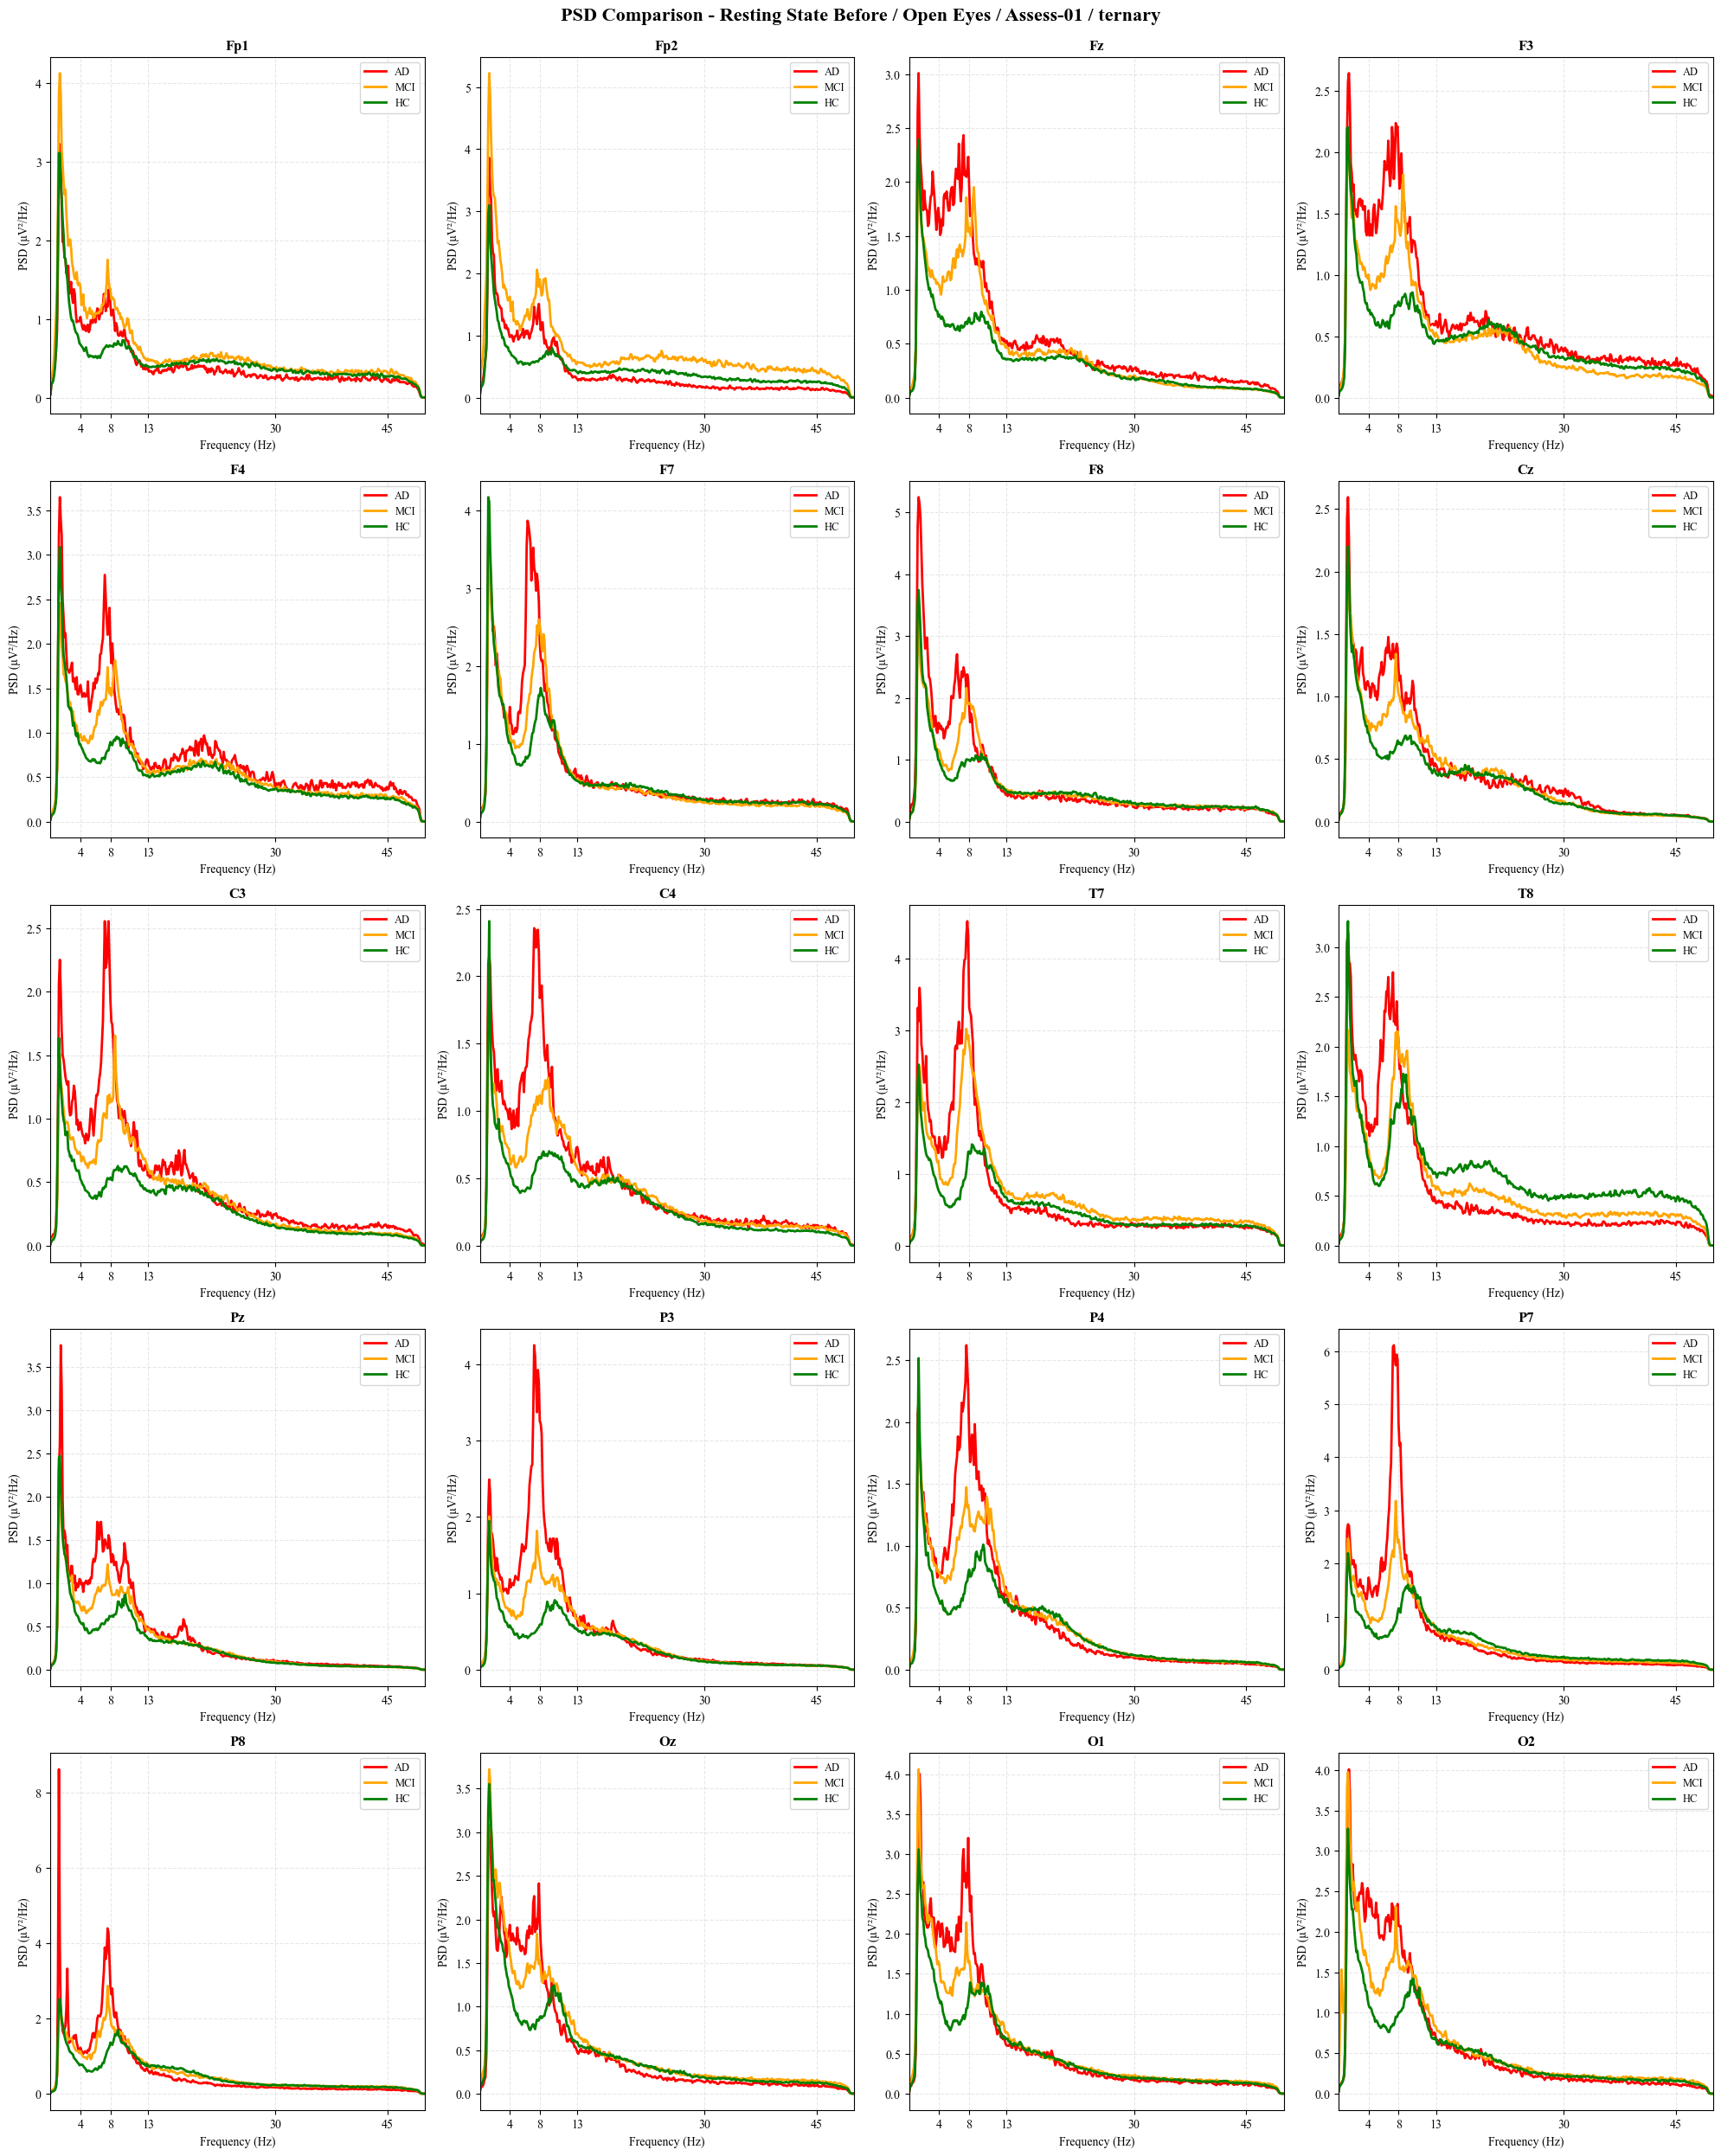

In [12]:
# 绘制三分类的对比图
plot_channel_psd_comparison(
    paradigm='resting state befor', 
    state='open eyes', 
    assess='Assess-01', 
    category_type='ternary',
    save_dir=save_path,
    # 字体大小（可选，以下为默认值）
    subplot_title_fontsize=12,   # 子图标题
    tick_fontsize=10,            # 横纵坐标刻度
    axis_label_fontsize=10,      # 横纵坐标标题
    legend_fontsize=9,           # 图例
)

PSD value range: min=2.71e-07, max=8.62e+00, mean=3.96e-01
Using unit: μV²/Hz
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_envelope_all_channels_resting_state_befor_open_eyes_Assess-01_ternary.svg


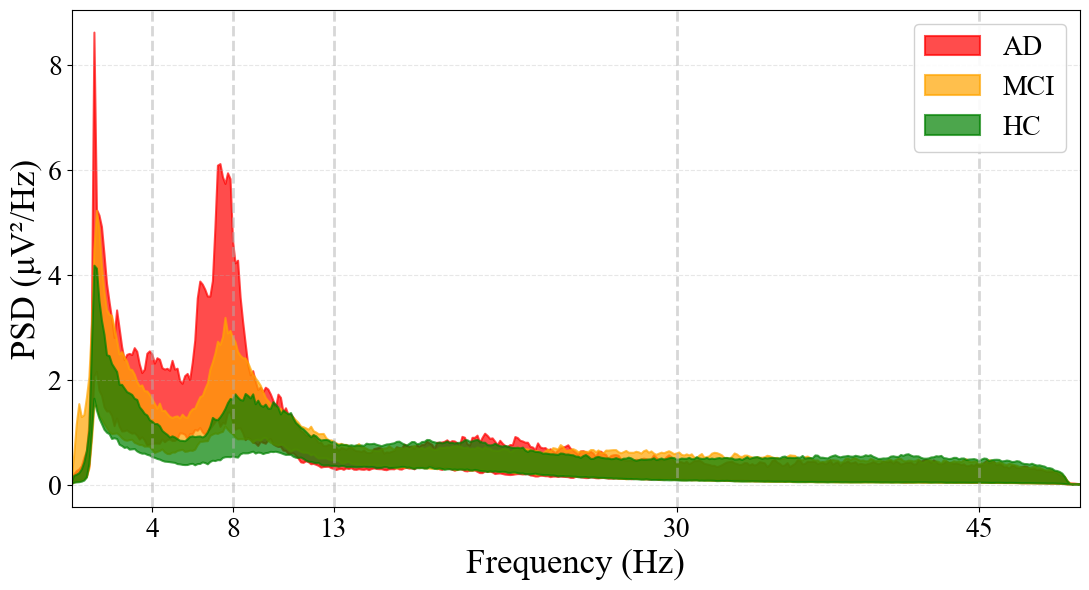

In [29]:
# 绘制所有通道叠加图（三分类）
plot_all_channels_overlay(
    paradigm='resting state befor', 
    state='open eyes', 
    assess='Assess-01', 
    category_type='ternary',
    save_dir=save_path,
    alpha=0.7,  # 线条透明度
    # 字体大小（可选，以下为默认值）
    subplot_title_fontsize=14,   # 图标题
    x_tick_fontsize=20,          # 横坐标刻度
    y_tick_fontsize=20,          # 纵坐标刻度
    xlabel_fontsize=25,          # 横坐标标题
    ylabel_fontsize=25,          # 纵坐标标题
    legend_fontsize=20,          # 图例
)

## 以下内容为模型中的 Adaptive Spectral Modulation (ASM) module 结构图绘制 提供图片材料

### 绘制多通道组合的 3D PSD 线图

In [17]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401


def _resolve_channel_indices(channels):
    """将通道名称或索引统一转换为 channel_order 中的索引列表。"""
    if channels is None:
        return list(range(len(channel_order)))

    resolved = []
    for ch in channels:
        if isinstance(ch, str):
            if ch not in channel_order:
                raise ValueError(f"未知通道名称: {ch}，可选: {channel_order}")
            resolved.append(channel_order.index(ch))
        else:
            ch_idx = int(ch)
            if ch_idx < 0 or ch_idx >= len(channel_order):
                raise ValueError(f"通道索引越界: {ch_idx}，有效范围 0-{len(channel_order) - 1}")
            resolved.append(ch_idx)
    return resolved


def plot_mci_psd_3d(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    category='MCI',
    category_type='ternary',
    channels=None,
    save_dir=None,
    freq_max=50,
    sfreq=128,
    figsize=(12, 8),
    elev=25,
    azim=-60,
    line_width=2.0,
    dpi=300,
):
    """
    绘制 MCI 类别平均 PSD 的三维线图，供 Adaptive Spectral Block 结构图使用。

    坐标轴:
    - x: 频率 (Hz)
    - y: 通道（按所选通道顺序排列）
    - z: PSD 幅值 (μV²/Hz)

    参数:
    - channels: 要绘制的通道，支持索引(int)或名称(str)，默认 10 个典型通道
    - save_dir: 图片保存目录，None 则不保存
    - freq_max: 频率显示上限 (Hz)
    """
    if channels is None:
        channels = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']

    channel_indices = _resolve_channel_indices(channels)
    if len(channel_indices) != 10:
        print(f"提示: 当前选择了 {len(channel_indices)} 个通道，建议绘制 10 个通道以便结构图展示。")

    # 获取频率数组（与 plot_channel_psd_comparison 保持一致）
    first_subject_data = None
    for _, psd_array in psd_normalized[paradigm][state][assess].items():
        first_subject_data = psd_array
        break

    if first_subject_data is None:
        print(f"Warning: No data found for {paradigm} / {state} / {assess}")
        return None

    _, n_freqs = first_subject_data.shape
    freqs = np.linspace(0, sfreq / 2, n_freqs)
    freq_mask = freqs <= freq_max
    freqs_plot = freqs[freq_mask]

    mci_psd = category_avg_psd[paradigm][state][assess][category_type].get(category, {})
    if not mci_psd:
        print(f"Warning: No {category} PSD data found for {paradigm} / {state} / {assess} / {category_type}")
        return None

    missing_channels = [ch_idx for ch_idx in channel_indices if ch_idx not in mci_psd]
    if missing_channels:
        missing_names = [channel_order[i] for i in missing_channels]
        print(f"Warning: 以下通道缺少 {category} 数据: {missing_names}")
        channel_indices = [ch_idx for ch_idx in channel_indices if ch_idx in mci_psd]
        if not channel_indices:
            return None

    # 颜色映射：沿通道渐变，便于区分
    cmap = plt.cm.viridis
    start, end = 0.55, 0.85
    colors = [cmap(start + (end - start) * i / max(len(channel_indices) - 1, 1)) for i in range(len(channel_indices))]

    fig = plt.figure(figsize=figsize, facecolor='white')
    ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
    ax.set_facecolor('white')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        axis._axinfo['grid']['linestyle'] = '--'
        axis._axinfo['grid']['color'] = (0.7, 0.7, 0.7, 0.6)

    all_psd_values = []
    # 先收集所有 PSD 数值
    for y_pos, ch_idx in enumerate(channel_indices):
        avg_psd = mci_psd[ch_idx][freq_mask]
        all_psd_values.extend(avg_psd.tolist())
    # 反向绘制：最后面的通道先画，最前面的通道最后画
    for y_pos in reversed(range(len(channel_indices))):
        ch_idx = channel_indices[y_pos]
        avg_psd = mci_psd[ch_idx][freq_mask]
        y_vals = np.full_like(freqs_plot, y_pos, dtype=float)
        ax.plot(
            freqs_plot,
            y_vals,
            avg_psd,
            color=colors[y_pos],
            linewidth=line_width,
            zorder=len(channel_indices) - y_pos,  # 前面的层级更高
        )

    ax.set_xlim(0, freq_max)
    ax.set_ylim(-0.5, len(channel_indices) - 0.5)

    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.grid(False)

    min_val, max_val, mean_val = np.min(all_psd_values), np.max(all_psd_values), np.mean(all_psd_values)
    print(f"{category} PSD value range: min={min_val:.2e}, max={max_val:.2e}, mean={mean_val:.2e}")
    print(f"Selected channels: {[channel_order[i] for i in channel_indices]}")

    plt.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        ch_tag = '_'.join(channel_order[i] for i in channel_indices)
        filename = (
            f'PSD_3D_{category}_{paradigm.replace(" ", "_")}_{state.replace(" ", "_")}_'
            f'{assess}_{ch_tag}.svg'
        )
        save_path_full = save_dir / filename
        fig.savefig(save_path_full, format='svg', bbox_inches='tight', facecolor='white',  pad_inches=0)
        print(f"Figure saved to: {save_path_full}")

    return fig, ax

MCI PSD value range: min=2.29e-04, max=5.22e+00, mean=4.95e-01
Selected channels: ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_3D_MCI_resting_state_befor_open_eyes_Assess-01_Fp1_Fp2_Fz_F3_F4_Cz_C3_C4_Pz_Oz.svg


(<Figure size 1200x800 with 1 Axes>, <Axes3D: >)

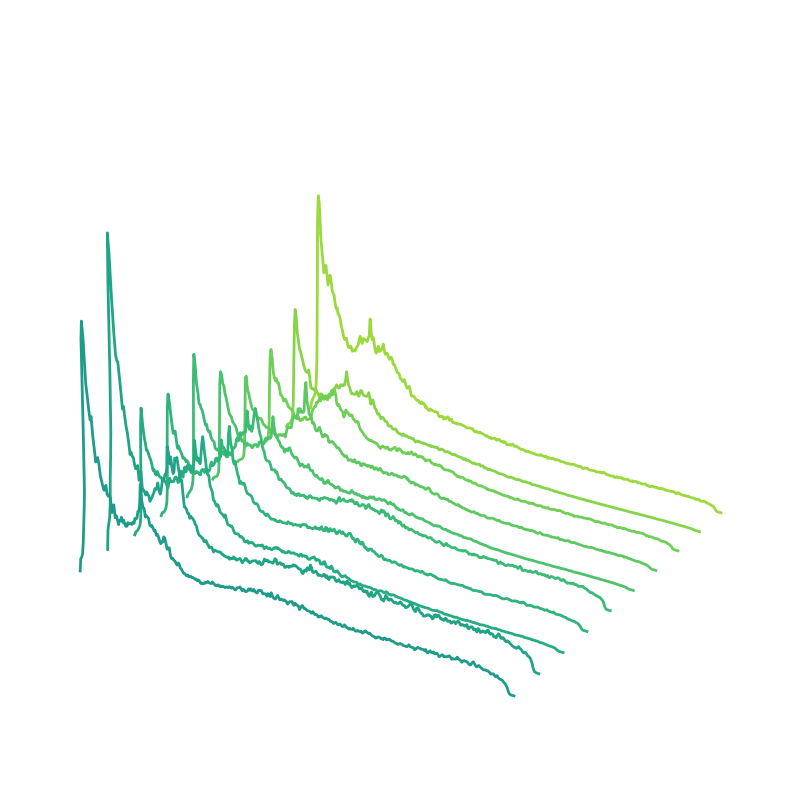

In [19]:
# 绘制 MCI 三分类数据的 3D PSD 线图（Adaptive Spectral Block 结构图素材）
# channels 支持通道名称(str)或索引(int)，可自由指定 10 个通道
plot_mci_psd_3d(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    category='MCI',
    category_type='ternary',
    # 方式1: 使用通道名称（推荐，直观）
    channels=['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz'],
    # 方式2: 使用通道索引，例如 channels=[0, 1, 2, 3, 4, 7, 8, 9, 12, 17]
    save_dir=save_path,
    freq_max=50,
    elev=25,
    azim=-60,
    dpi=600
)

### 带 z 轴阈值平面的 3D PSD 图

在 `plot_mci_psd_3d` 基础上新增：添加灰色阈值平面，**低于平面**的曲线段为灰色，**高于平面**的曲线段保留 viridis 通道原色。

In [20]:
# 全局变量：每个通道中 PSD 低于阈值的频率 (Hz)
# 结构: {通道名: np.ndarray([freq1, freq2, ...])}
below_threshold_freqs_by_channel = {}


def _plot_channel_psd_split_by_threshold(ax, freqs, y_val, psd, color, threshold,
                                         line_width=2.0, below_color=(0.65, 0.65, 0.65, 1.0), zorder=1):
    """按阈值将单通道 PSD 曲线拆分为灰色（低于平面）与彩色（高于平面）两段绘制。"""
    for i in range(len(freqs) - 1):
        x0, x1 = freqs[i], freqs[i + 1]
        z0, z1 = psd[i], psd[i + 1]
        below0, below1 = z0 <= threshold, z1 <= threshold

        if below0 and below1:
            ax.plot([x0, x1], [y_val, y_val], [z0, z1], color=below_color, linewidth=line_width, zorder=zorder)
        elif (not below0) and (not below1):
            ax.plot([x0, x1], [y_val, y_val], [z0, z1], color=color, linewidth=line_width, zorder=zorder)
        else:
            if abs(z1 - z0) < 1e-12:
                seg_color = below_color if below0 else color
                ax.plot([x0, x1], [y_val, y_val], [z0, z1], color=seg_color, linewidth=line_width, zorder=zorder)
                continue
            t = (threshold - z0) / (z1 - z0)
            xc = x0 + t * (x1 - x0)
            zc = threshold
            if below0:
                ax.plot([x0, xc], [y_val, y_val], [z0, zc], color=below_color, linewidth=line_width, zorder=zorder)
                ax.plot([xc, x1], [y_val, y_val], [zc, z1], color=color, linewidth=line_width, zorder=zorder)
            else:
                ax.plot([x0, xc], [y_val, y_val], [z0, zc], color=color, linewidth=line_width, zorder=zorder)
                ax.plot([xc, x1], [y_val, y_val], [zc, z1], color=below_color, linewidth=line_width, zorder=zorder)


def plot_mci_psd_3d_with_threshold_plane(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    category='MCI',
    category_type='ternary',
    channels=None,
    save_dir=None,
    freq_max=50,
    sfreq=128,
    figsize=(12, 8),
    elev=25,
    azim=-60,
    line_width=2.0,
    dpi=300,
    z_threshold=None,
    threshold_offset=0.0,
    draw_plane=True,
    plane_color=(0.75, 0.75, 0.75, 0.45),
    below_color=(0.65, 0.65, 0.65, 1.0),
):
    """
    在 plot_mci_psd_3d 基础上绘制带 z 轴阈值平面的 3D PSD 图。

    - 灰色平面：z = z_threshold（未指定时为 PSD 均值 + threshold_offset）
    - 低于平面：灰色
    - 高于平面：通道原色

    参数:
    - threshold_offset: 阈值微调量，在 PSD 均值基础上加减（z_threshold 为 None 时生效）
    - draw_plane: 是否绘制灰色阈值平面

    全局变量:
    - below_threshold_freqs_by_channel: 绘图后更新，记录各通道低于阈值的频率 (Hz)
    """
    global below_threshold_freqs_by_channel
    below_threshold_freqs_by_channel = {}

    if channels is None:
        channels = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']

    channel_indices = _resolve_channel_indices(channels)
    if len(channel_indices) != 10:
        print(f"提示: 当前选择了 {len(channel_indices)} 个通道，建议绘制 10 个通道以便结构图展示。")

    first_subject_data = None
    for _, psd_array in psd_normalized[paradigm][state][assess].items():
        first_subject_data = psd_array
        break

    if first_subject_data is None:
        print(f"Warning: No data found for {paradigm} / {state} / {assess}")
        return None

    _, n_freqs = first_subject_data.shape
    freqs = np.linspace(0, sfreq / 2, n_freqs)
    freq_mask = freqs <= freq_max
    freqs_plot = freqs[freq_mask]

    mci_psd = category_avg_psd[paradigm][state][assess][category_type].get(category, {})
    if not mci_psd:
        print(f"Warning: No {category} PSD data found for {paradigm} / {state} / {assess} / {category_type}")
        return None

    missing_channels = [ch_idx for ch_idx in channel_indices if ch_idx not in mci_psd]
    if missing_channels:
        missing_names = [channel_order[i] for i in missing_channels]
        print(f"Warning: 以下通道缺少 {category} 数据: {missing_names}")
        channel_indices = [ch_idx for ch_idx in channel_indices if ch_idx in mci_psd]
        if not channel_indices:
            return None

    # 颜色映射：沿通道渐变，便于区分
    cmap = plt.cm.viridis
    start, end = 0.55, 0.85
    colors = [cmap(start + (end - start) * i / max(len(channel_indices) - 1, 1)) for i in range(len(channel_indices))]

    all_psd_values = []
    channel_psd_list = []
    for ch_idx in channel_indices:
        avg_psd = mci_psd[ch_idx][freq_mask]
        channel_psd_list.append(avg_psd)
        all_psd_values.extend(avg_psd.tolist())

    mean_psd = float(np.mean(all_psd_values))
    if z_threshold is None:
        z_threshold = mean_psd + threshold_offset
    else:
        z_threshold = float(z_threshold)

    for y_pos, ch_idx in enumerate(channel_indices):
        ch_name = channel_order[ch_idx]
        avg_psd = channel_psd_list[y_pos]
        below_mask = avg_psd <= z_threshold
        below_threshold_freqs_by_channel[ch_name] = freqs_plot[below_mask].copy()

    fig = plt.figure(figsize=figsize, facecolor='white')
    ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
    ax.set_facecolor('white')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        axis._axinfo['grid']['linestyle'] = '--'
        axis._axinfo['grid']['color'] = (0.7, 0.7, 0.7, 0.6)

    n_channels = len(channel_indices)
    y_min, y_max = -0.5, n_channels - 0.5
    if draw_plane:
        xx, yy = np.meshgrid(np.linspace(0, freq_max, 2), np.linspace(y_min, y_max, 2))
        zz = np.full_like(xx, z_threshold)
        ax.plot_surface(xx, yy, zz, color=plane_color[:3], alpha=plane_color[3],
                        shade=False, edgecolor='none', zorder=0)

    for y_pos in reversed(range(n_channels)):
        avg_psd = channel_psd_list[y_pos]
        y_val = float(y_pos)
        _plot_channel_psd_split_by_threshold(
            ax, freqs_plot, y_val, avg_psd, colors[y_pos], z_threshold,
            line_width=line_width, below_color=below_color,
            zorder=n_channels - y_pos + 1,
        )

    ax.set_xlim(0, freq_max)
    ax.set_ylim(y_min, y_max)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.grid(False)

    min_val, max_val, mean_val = np.min(all_psd_values), np.max(all_psd_values), mean_psd
    print(f"{category} PSD value range: min={min_val:.2e}, max={max_val:.2e}, mean={mean_val:.2e}")
    print(f"Threshold z = {z_threshold:.2e} (mean + offset={threshold_offset:.2e})")
    print(f"Selected channels: {[channel_order[i] for i in channel_indices]}")
    for ch_name, below_freqs in below_threshold_freqs_by_channel.items():
        print(f"  {ch_name}: {len(below_freqs)} freqs below threshold")

    plt.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        ch_tag = '_'.join(channel_order[i] for i in channel_indices)
        filename = (
            f'PSD_3D_threshold_{category}_{paradigm.replace(" ", "_")}_{state.replace(" ", "_")}_'
            f'{assess}_{ch_tag}.svg'
        )
        save_path_full = save_dir / filename
        fig.savefig(save_path_full, format='svg', bbox_inches='tight', facecolor='white')
        print(f"Figure saved to: {save_path_full}")

    return fig, ax

MCI PSD value range: min=2.29e-04, max=5.22e+00, mean=4.95e-01
Threshold z = 5.95e-01 (mean + offset=1.00e-01)
Selected channels: ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']
  Fp1: 309 freqs below threshold
  Fp2: 218 freqs below threshold
  Fz: 313 freqs below threshold
  F3: 312 freqs below threshold
  F4: 243 freqs below threshold
  Cz: 309 freqs below threshold
  C3: 303 freqs below threshold
  C4: 307 freqs below threshold
  Pz: 314 freqs below threshold
  Oz: 293 freqs below threshold
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_3D_threshold_MCI_resting_state_befor_open_eyes_Assess-01_Fp1_Fp2_Fz_F3_F4_Cz_C3_C4_Pz_Oz.svg


(<Figure size 1200x800 with 1 Axes>, <Axes3D: >)

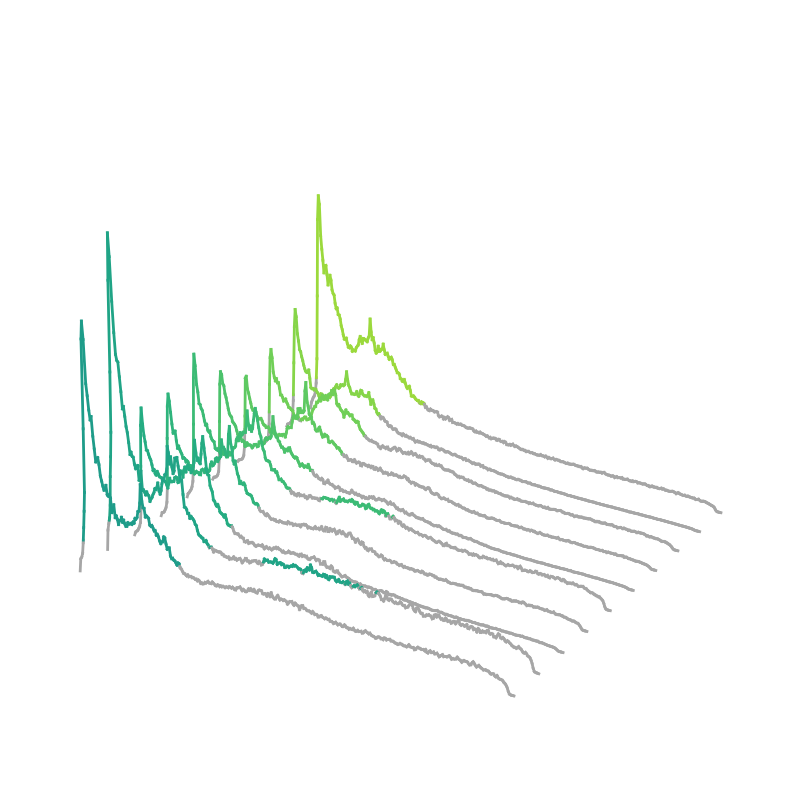

In [21]:
# 绘制带 z 轴阈值平面的 3D PSD 图（Adaptive Spectral Block 结构图素材）
plot_mci_psd_3d_with_threshold_plane(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    category='MCI',
    category_type='ternary',
    channels=['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz'],
    save_dir=save_path,
    freq_max=50,
    elev=25,
    azim=-60,
    threshold_offset=0.1,   # 在 PSD 均值基础上微调阈值，例如 0.1 或 -0.05
    draw_plane=False,          # False 时不绘制灰色平面，仅保留曲线分段着色
    dpi=600
)

### 随机 3D 柱状图

与 `plot_mci_psd_3d` 视觉风格一致，z 值为 [0, 1] 随机数；每个通道在 x-z 平面上绘制柱状图，柱子在 y 轴方向无厚度。

In [22]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.colors import to_rgba


def _thin_bar_quads(x_left, dx, y_val, z_heights):
    """生成 y 方向无厚度的柱状图四边形（位于 x-z 平面）。"""
    polys = []
    y = float(y_val)
    for i in range(len(z_heights)):
        x0 = float(x_left[i])
        x1 = x0 + float(dx)
        z1 = float(z_heights[i])
        polys.append([(x0, y, 0.0), (x1, y, 0.0), (x1, y, z1), (x0, y, z1)])
    return polys


def plot_random_step_psd_3d(
    n_channels=10,
    freq_max=50,
    n_steps=32,
    save_dir=None,
    figsize=(12, 8),
    elev=25,
    azim=-60,
    bar_width_ratio=0.85,
    bar_alpha=1.0,
    dpi=300,
    random_seed=None,
):
    """
    绘制随机 [0, 1] 数据的 3D 柱状图，风格与 plot_mci_psd_3d 一致。
    每个柱子在 y 轴方向无厚度，仅沿 x-z 平面竖立。

    坐标轴范围:
    - x: [0, freq_max]
    - y: [-0.5, n_channels - 0.5]
    - z: [0, 1]
    """
    rng = np.random.default_rng(random_seed)

    step_x = freq_max / n_steps
    dx = step_x * bar_width_ratio
    x_left = np.arange(n_steps) * step_x + (step_x - dx) / 2

    # 颜色映射：沿通道渐变，便于区分
    cmap = plt.cm.viridis
    start, end = 0.35, 0.85
    colors = [cmap(start + (end - start) * i / max(n_channels - 1, 1)) for i in range(n_channels)]

    fig = plt.figure(figsize=figsize, facecolor='white')
    ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
    ax.set_facecolor('white')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        axis._axinfo['grid']['linestyle'] = '--'
        axis._axinfo['grid']['color'] = (0.7, 0.7, 0.7, 0.6)

    all_values = []
    for y_pos in reversed(range(n_channels)):
        z_heights = rng.uniform(0.0, 1.0, size=n_steps)
        all_values.extend(z_heights.tolist())
        polys = _thin_bar_quads(x_left, dx, y_pos, z_heights)
        layer_zorder = n_channels - y_pos
        collection = Poly3DCollection(
            polys,
            facecolors=[to_rgba(colors[y_pos], bar_alpha)] * len(polys),
            edgecolors='none',
        )
        collection.set_zsort('average')
        collection.set_zorder(layer_zorder)
        ax.add_collection3d(collection)

    ax.set_xlim(0, freq_max)
    ax.set_ylim(-0.5, n_channels - 0.5)
    ax.set_zlim(0, 1)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.grid(False)

    min_val, max_val, mean_val = np.min(all_values), np.max(all_values), np.mean(all_values)
    print(f"Random value range: min={min_val:.4f}, max={max_val:.4f}, mean={mean_val:.4f}")
    print(f"Channels: {n_channels}, x in [0, {freq_max}], y in [-0.5, {n_channels - 0.5}]")

    plt.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        filename = f'PSD_3D_random_bar_{n_channels}ch_freq{freq_max}.svg'
        save_path_full = save_dir / filename
        fig.savefig(save_path_full, format='svg', bbox_inches='tight', facecolor='white')
        print(f"Figure saved to: {save_path_full}")

    return fig, ax

Random value range: min=0.0074, max=0.9924, mean=0.4850
Channels: 10, x in [0, 50], y in [-0.5, 9.5]
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_3D_random_bar_10ch_freq50.svg


(<Figure size 1200x800 with 1 Axes>, <Axes3D: >)

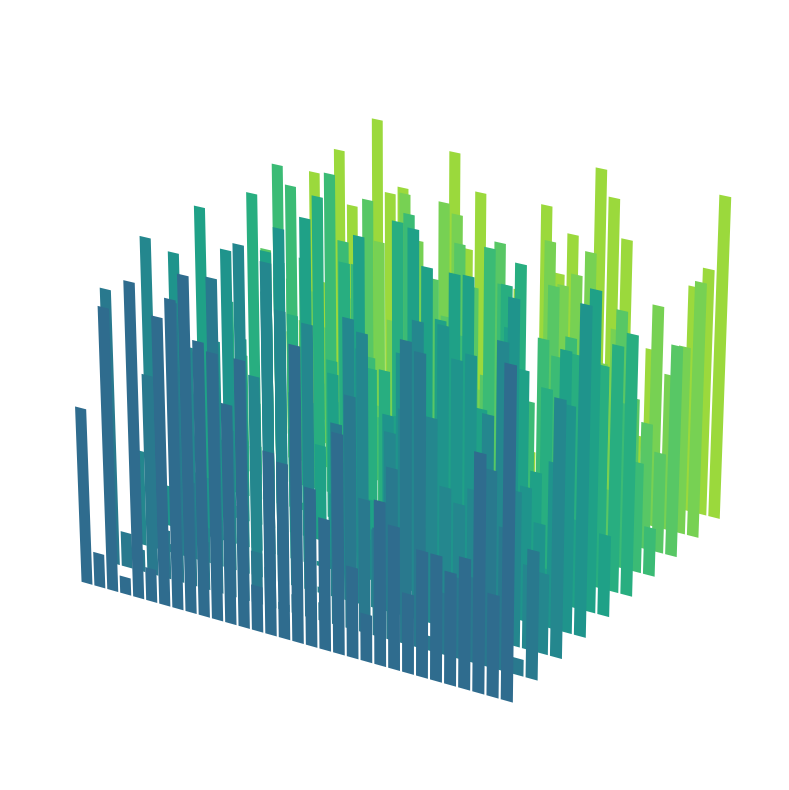

In [23]:
# 绘制随机 [0, 1] 3D 柱状图（y 方向无厚度，Adaptive Spectral Block 结构图素材）
plot_random_step_psd_3d(
    n_channels=10,
    freq_max=50,
    n_steps=32,
    save_dir=save_path,
    elev=25,
    azim=-60,
    random_seed=42,
    dpi=600
)

## 带 z 轴阈值的随机 3D 柱状图

- **高于阈值频率**（不在 `below_threshold_freqs_by_channel` 中）：viridis 通道原色柱
- **低于阈值频率**（在 `below_threshold_freqs_by_channel` 中）：灰色半透明柱

In [24]:
def _bar_center_freqs(x_left, dx):
    return x_left + dx / 2


def _is_freq_in_below_set(freq, below_freqs, tol):
    if below_freqs is None or len(below_freqs) == 0:
        return False
    return bool(np.any(np.abs(below_freqs - freq) <= tol))


def plot_random_bar_3d_with_threshold(
    channels=None,
    freq_max=50,
    n_steps=32,
    save_dir=None,
    figsize=(12, 8),
    elev=25,
    azim=-60,
    bar_width_ratio=0.85,
    bar_alpha=1.0,
    dpi=300,
    random_seed=None,
    z_threshold=None,
    threshold_offset=0.0,
    draw_plane=False,
    plane_color=(0.75, 0.75, 0.75, 0.45),
    below_bar_color=(0.65, 0.65, 0.65),
    below_bar_alpha=0.35,
    freq_match_tol=None,
):
    """
    绘制带 z 轴阈值的随机 3D 柱状图（y 方向无厚度）。

    - below_threshold_freqs_by_channel 中的频率 → 灰色半透明柱
    - 其余频率 → 通道 viridis 原色柱
    - below_bar_alpha: 低于阈值灰色柱的透明度（0~1）
    需先运行 plot_mci_psd_3d_with_threshold_plane 以填充该全局变量。
    """
    if channels is None:
        channels = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']

    if not below_threshold_freqs_by_channel:
        print('Warning: below_threshold_freqs_by_channel 为空，请先运行 plot_mci_psd_3d_with_threshold_plane')

    channel_indices = _resolve_channel_indices(channels)
    channel_names = [channel_order[i] for i in channel_indices]
    n_channels = len(channel_names)

    rng = np.random.default_rng(random_seed)
    step_x = freq_max / n_steps
    dx = step_x * bar_width_ratio
    x_left = np.arange(n_steps) * step_x + (step_x - dx) / 2
    bar_freqs = _bar_center_freqs(x_left, dx)
    if freq_match_tol is None:
        freq_match_tol = step_x / 2

    # 颜色映射：沿通道渐变，便于区分
    cmap = plt.cm.viridis
    start, end = 0.35, 0.85
    colors = [cmap(start + (end - start) * i / max(n_channels - 1, 1)) for i in range(n_channels)]


    fig = plt.figure(figsize=figsize, facecolor='white')
    ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
    ax.set_facecolor('white')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 1.0))
        axis._axinfo['grid']['linestyle'] = '--'
        axis._axinfo['grid']['color'] = (0.7, 0.7, 0.7, 0.6)

    y_min, y_max = -0.5, n_channels - 0.5

    all_values = []
    colored_bar_count = 0
    gray_bar_count = 0
    for y_pos in reversed(range(n_channels)):
        ch_name = channel_names[y_pos]
        below_freqs = below_threshold_freqs_by_channel.get(ch_name, np.array([]))
        below_mask = np.array([
            _is_freq_in_below_set(bar_freqs[i], below_freqs, freq_match_tol)
            for i in range(n_steps)
        ], dtype=bool)
        keep_mask = ~below_mask
        layer_zorder = n_channels - y_pos + 1

        if np.any(below_mask):
            x_below = x_left[below_mask]
            z_below = rng.uniform(0.0, 1.0, size=int(below_mask.sum()))
            all_values.extend(z_below.tolist())
            gray_bar_count += len(z_below)
            polys_below = _thin_bar_quads(x_below, dx, y_pos, z_below)
            coll_below = Poly3DCollection(
                polys_below,
                facecolors=[to_rgba(below_bar_color, below_bar_alpha)] * len(polys_below),
                edgecolors='none',
            )
            coll_below.set_zsort('average')
            coll_below.set_zorder(layer_zorder)
            ax.add_collection3d(coll_below)

        if np.any(keep_mask):
            x_keep = x_left[keep_mask]
            z_heights = rng.uniform(0.0, 1.0, size=int(keep_mask.sum()))
            all_values.extend(z_heights.tolist())
            colored_bar_count += len(z_heights)
            polys = _thin_bar_quads(x_keep, dx, y_pos, z_heights)
            coll = Poly3DCollection(
                polys,
                facecolors=[to_rgba(colors[y_pos], bar_alpha)] * len(polys),
                edgecolors='none',
            )
            coll.set_zsort('average')
            coll.set_zorder(layer_zorder + 1)
            ax.add_collection3d(coll)

        print(
            f"  {ch_name}: 灰色柱 {int(below_mask.sum())} 个, "
            f"彩色柱 {int(keep_mask.sum())} 个 / 共 {n_steps} 个频率"
        )

    if not all_values:
        print('Warning: 没有可绘制的频率柱')
        return None

    mean_val = float(np.mean(all_values))
    if z_threshold is None:
        z_threshold = mean_val + threshold_offset
    else:
        z_threshold = float(z_threshold)

    if draw_plane:
        xx, yy = np.meshgrid(np.linspace(0, freq_max, 2), np.linspace(y_min, y_max, 2))
        zz = np.full_like(xx, z_threshold)
        ax.plot_surface(xx, yy, zz, color=plane_color[:3], alpha=plane_color[3],
                        shade=False, edgecolor='none', zorder=0)

    ax.set_xlim(0, freq_max)
    ax.set_ylim(y_min, y_max)
    ax.set_zlim(0, 1)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.grid(False)

    min_val, max_val = np.min(all_values), np.max(all_values)
    print(f"Random value range: min={min_val:.4f}, max={max_val:.4f}, mean={mean_val:.4f}")
    print(f"Threshold z = {z_threshold:.4f}")
    print(f"Gray bars: {gray_bar_count}, Colored bars: {colored_bar_count}")
    print(f"Channels: {channel_names}")

    plt.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        filename = f'PSD_3D_random_bar_threshold_{n_channels}ch_freq{freq_max}.svg'
        save_path_full = save_dir / filename
        fig.savefig(save_path_full, format='svg', bbox_inches='tight', facecolor='white')
        print(f"Figure saved to: {save_path_full}")

    return fig, ax

  Oz: 灰色柱 25 个, 彩色柱 7 个 / 共 32 个频率
  Pz: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
  C4: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
  C3: 灰色柱 25 个, 彩色柱 7 个 / 共 32 个频率
  Cz: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
  F4: 灰色柱 22 个, 彩色柱 10 个 / 共 32 个频率
  F3: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
  Fz: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
  Fp2: 灰色柱 22 个, 彩色柱 10 个 / 共 32 个频率
  Fp1: 灰色柱 26 个, 彩色柱 6 个 / 共 32 个频率
Random value range: min=0.0074, max=0.9924, mean=0.4850
Threshold z = 0.4850
Gray bars: 250, Colored bars: 70
Channels: ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz']
Figure saved to: C:\Python_Code\ADMamba\figs\PSD_3D_random_bar_threshold_10ch_freq50.svg


(<Figure size 1200x800 with 1 Axes>, <Axes3D: >)

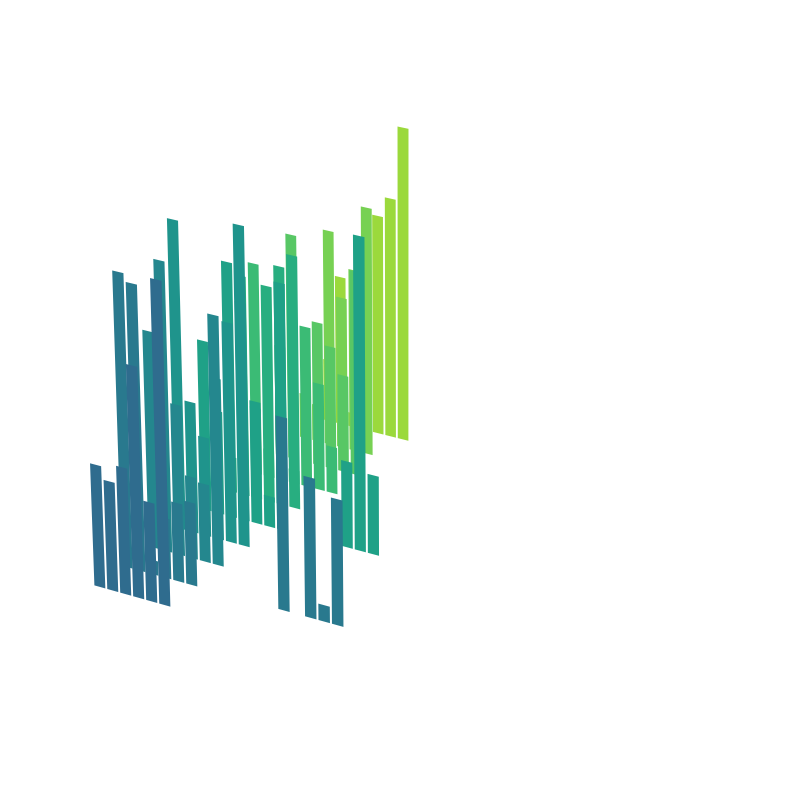

In [25]:
# 绘制带 z 轴阈值的随机 3D 柱状图（需先运行 plot_mci_psd_3d_with_threshold_plane）
plot_random_bar_3d_with_threshold(
    channels=['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'Cz', 'C3', 'C4', 'Pz', 'Oz'],
    freq_max=50,
    n_steps=32,
    save_dir=save_path,
    elev=25,
    azim=-60,
    random_seed=42,
    threshold_offset=0.0,
    below_bar_alpha=0.0,   # 低于阈值灰色柱的透明度，0=全透明，1=不透明
    dpi=600
)